In [7]:
import kagglehub
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import warnings
warnings.filterwarnings('ignore')

# Загрузка датасета
path = kagglehub.dataset_download(
    "nasa/kepler-exoplanet-search-results"
)

dataset_path = Path(path)

print("Датасет загружен:", dataset_path)

100%|██████████| 1.16M/1.16M [00:00<00:00, 1.70MB/s]

Extracting files...
Датасет загружен: C:\Users\yaros_tm2sc6p\.cache\kagglehub\datasets\nasa\kepler-exoplanet-search-results\versions\2


In [8]:
csv_files = list(dataset_path.rglob("*.csv"))

print("Найденные CSV-файлы:")

for file in csv_files:
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

Найденные CSV-файлы:
cumulative.csv - 3608.71 KB


In [9]:
# Ищем основной файл
main_file = next(
    (f for f in csv_files if f.name.lower() == "cumulative.csv"),
    None
)

if main_file is None:
    raise FileNotFoundError(
        "cumulative.csv не найден. Проверь список файлов выше."
    )

df = pd.read_csv(main_file)

print("Файл:", main_file.name)
print("Размер датасета:", df.shape)

display(df.head())

Файл: cumulative.csv
Размер датасета: (9564, 50)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [10]:
print("Распределение классов:")

print(df['koi_disposition'].value_counts(dropna=False))

print("\nКоличество признаков:", df.shape[1])
print("Количество объектов:", df.shape[0])

print("\nТипы данных:")
print(df.dtypes)

Распределение классов:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64

Количество признаков: 50
Количество объектов: 9564

Типы данных:
rowid                  int64
kepid                  int64
kepoi_name               str
kepler_name              str
koi_disposition          str
koi_pdisposition         str
koi_score            float64
koi_fpflag_nt          int64
koi_fpflag_ss          int64
koi_fpflag_co          int64
koi_fpflag_ec          int64
koi_period           float64
koi_period_err1      float64
koi_period_err2      float64
koi_time0bk          float64
koi_time0bk_err1     float64
koi_time0bk_err2     float64
koi_impact           float64
koi_impact_err1      float64
koi_impact_err2      float64
koi_duration         float64
koi_duration_err1    float64
koi_duration_err2    float64
koi_depth            float64
koi_depth_err1       float64
koi_depth_err2       float64
koi_prad             float64
koi_prad_err1    

Распределение классов:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


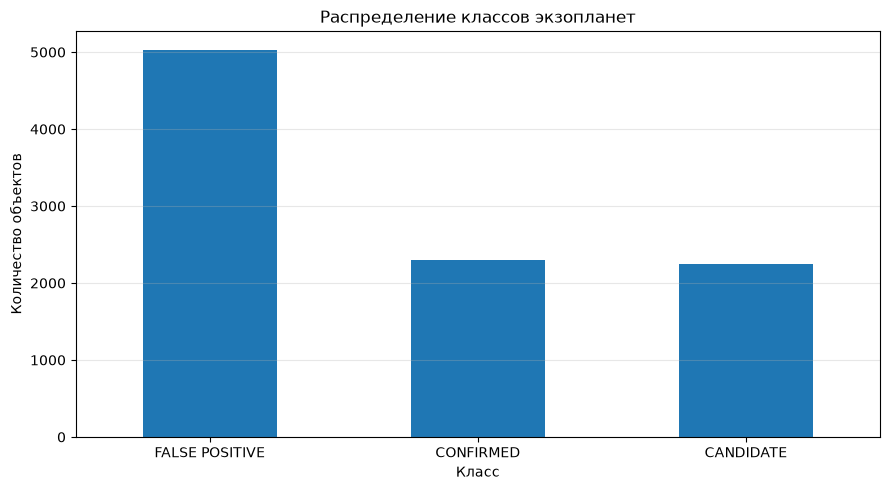

In [12]:
print("Распределение классов:")

print(df['koi_disposition'].value_counts())

plt.figure(figsize=(9, 5))

df['koi_disposition'].value_counts().plot(
    kind='bar',
    rot=0
)

plt.title('Распределение классов экзопланет')
plt.xlabel('Класс')
plt.ylabel('Количество объектов')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('kepler_classes.png', dpi=300)
plt.show()

In [13]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

print("Столбцы с пропущенными значениями:")
display(missing.to_frame(name='Количество пропусков'))

Столбцы с пропущенными значениями:


,Количество пропусков
koi_teq_err1,9564
koi_teq_err2,9564
kepler_name,7270
koi_score,1510
koi_steff_err2,483
koi_slogg_err1,468
koi_slogg_err2,468
koi_srad_err2,468
koi_steff_err1,468
koi_srad_err1,468


In [14]:
# Целевая переменная
y = df['koi_disposition'].copy()

# Выбираем физические и наблюдаемые характеристики
feature_cols = [
    'koi_period',
    'koi_impact',
    'koi_duration',
    'koi_depth',
    'koi_prad',
    'koi_teq',
    'koi_insol',
    'koi_model_snr',
    'koi_steff',
    'koi_slogg',
    'koi_srad',
    'koi_kepmag'
]

# Формируем матрицу признаков
X = df[feature_cols].copy()

# Преобразуем значения в числовой формат
X = X.apply(pd.to_numeric, errors='coerce')

# Обрабатываем бесконечные значения
X = X.replace([np.inf, -np.inf], np.nan)

print("Размер матрицы признаков:", X.shape)
print("Количество классов:", y.nunique())

display(X.head())

Размер матрицы признаков: (9564, 12)
Количество классов: 3


,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_steff,koi_slogg,koi_srad,koi_kepmag
0,9.488036,0.146,2.95750,615.8,2.26,793.0,93.59,35.8,5455.0,4.467,0.927,15.347
1,54.418383,0.586,4.50700,874.8,2.83,443.0,9.11,25.8,5455.0,4.467,0.927,15.347
2,19.899140,0.969,1.78220,10829.0,14.60,638.0,39.30,76.3,5853.0,4.544,0.868,15.436
3,1.736952,1.276,2.40641,8079.2,33.46,1395.0,891.96,505.6,5805.0,4.564,0.791,15.597
4,2.525592,0.701,1.65450,603.3,2.75,1406.0,926.16,40.9,6031.0,4.438,1.046,15.509


In [15]:
# Проверяем пропуски до обработки
print("Пропуски до обработки:")
print(X.isnull().sum())

# Заполняем пропуски медианными значениями
X = X.fillna(X.median())

print("\nПропуски после обработки:")
print(X.isnull().sum().sum())

print("\nИтоговый размер:", X.shape)

Пропуски до обработки:
koi_period         0
koi_impact       363
koi_duration       0
koi_depth        363
koi_prad         363
koi_teq          363
koi_insol        321
koi_model_snr    363
koi_steff        363
koi_slogg        363
koi_srad         363
koi_kepmag         1
dtype: int64

Пропуски после обработки:
0

Итоговый размер: (9564, 12)


In [16]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Размерность:", X_scaled.shape)
print("Среднее:", X_scaled.mean().round(4))
print("Стандартное отклонение:", X_scaled.std().round(4))

Размерность: (9564, 12)
Среднее: 0.0
Стандартное отклонение: 1.0


In [17]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("PC1:",
      round(explained_variance[0] * 100, 2), "%")

print("PC2:",
      round(explained_variance[1] * 100, 2), "%")

print("Общая объяснённая дисперсия:",
      round(explained_variance.sum() * 100, 2), "%")

PC1: 21.89 %
PC2: 14.2 %
Общая объяснённая дисперсия: 36.09 %


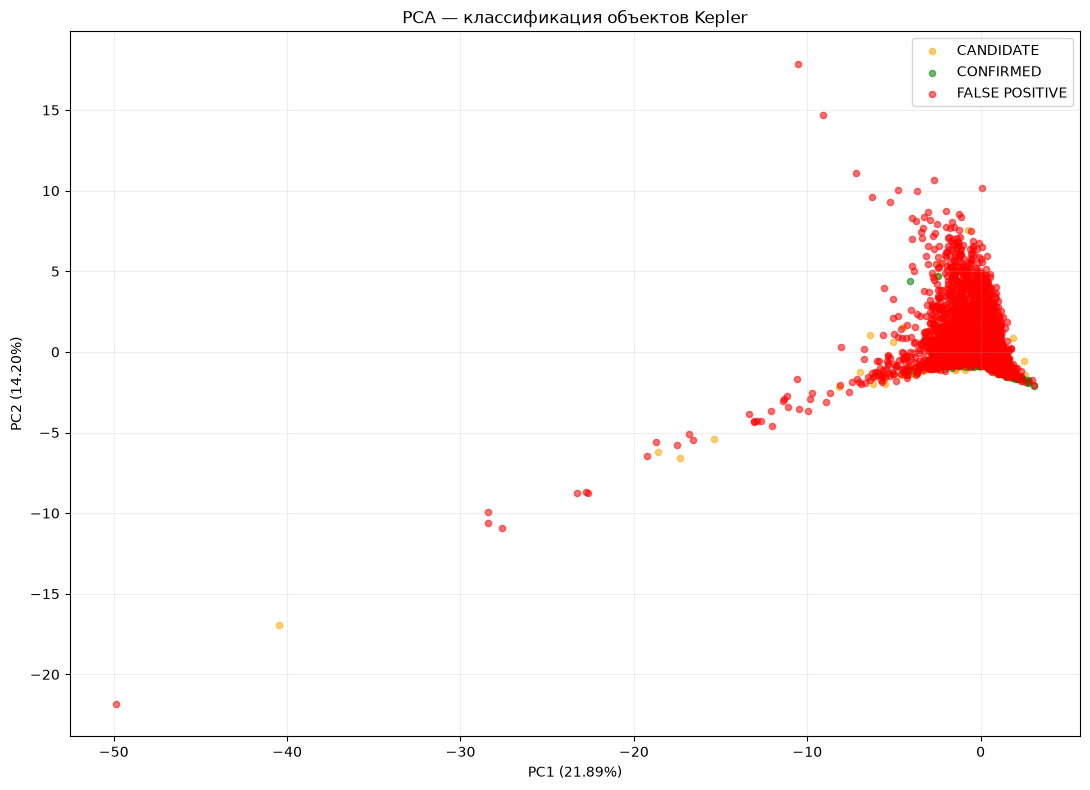

In [18]:
plt.figure(figsize=(11, 8))

colors = {
    'CONFIRMED': 'green',
    'CANDIDATE': 'orange',
    'FALSE POSITIVE': 'red'
}

for genre in sorted(y.unique()):
    mask = (y.to_numpy() == genre)

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=genre,
        color=colors[genre],
        alpha=0.55,
        s=20
    )

plt.title('PCA — классификация объектов Kepler')
plt.xlabel(f'PC1 ({explained_variance[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({explained_variance[1]*100:.2f}%)')

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig('PCA.png', dpi=300)
plt.show()

In [19]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

print("Размерность после t-SNE:", X_tsne.shape)

Размерность после t-SNE: (9564, 2)


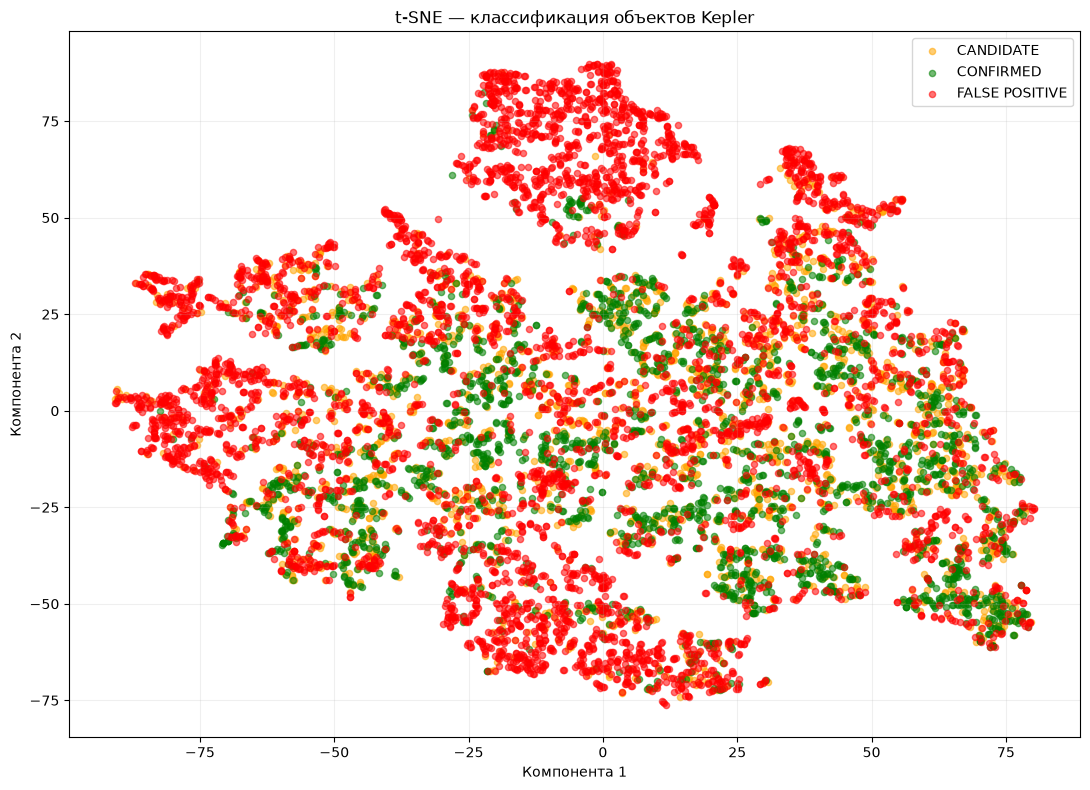

In [20]:
plt.figure(figsize=(11, 8))

for genre in sorted(y.unique()):
    mask = (y.to_numpy() == genre)

    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        label=genre,
        color=colors[genre],
        alpha=0.55,
        s=20
    )

plt.title('t-SNE — классификация объектов Kepler')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig('t-SNE.png', dpi=300)
plt.show()

In [21]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [22]:
# Целевой признак
y = df['koi_disposition'].copy()

# Выбранные признаки
feature_cols = [
    'koi_period',
    'koi_impact',
    'koi_duration',
    'koi_depth',
    'koi_prad',
    'koi_teq',
    'koi_insol',
    'koi_model_snr',
    'koi_steff',
    'koi_slogg',
    'koi_srad',
    'koi_kepmag'
]

# Формируем исходную матрицу признаков
X = df[feature_cols].copy()

# Преобразуем значения в числовой формат
X = X.apply(pd.to_numeric, errors='coerce')

# Заменяем бесконечности на пропуски
X = X.replace([np.inf, -np.inf], np.nan)

# Удаляем объекты без целевого класса
valid = y.notna()

X = X.loc[valid]
y = y.loc[valid]

print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])
print("Количество классов:", y.nunique())

Количество объектов: 9564
Количество признаков: 12
Количество классов: 3


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

print("\nКлассы в обучающей выборке:")
print(y_train.value_counts())

print("\nКлассы в тестовой выборке:")
print(y_test.value_counts())

Обучающая выборка: (7651, 12)
Тестовая выборка: (1913, 12)

Классы в обучающей выборке:
koi_disposition
FALSE POSITIVE    4018
CONFIRMED         1834
CANDIDATE         1799
Name: count, dtype: int64

Классы в тестовой выборке:
koi_disposition
FALSE POSITIVE    1005
CONFIRMED          459
CANDIDATE          449
Name: count, dtype: int64


In [24]:
models = {
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]),

    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),

    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', GradientBoostingClassifier(random_state=42))
    ]),

    'KNN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier())
    ])
}

print("Созданы четыре классификатора:")
for name in models:
    print("-", name)

Созданы четыре классификатора:
- Decision Tree
- Random Forest
- Gradient Boosting
- KNN


In [25]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

cv_results = []

for name, model in models.items():

    print(f"\nОбучение: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    cv_results.append({
        'Модель': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean()
    })

cv_table = pd.DataFrame(cv_results)

display(cv_table.round(4))


Обучение: Decision Tree

Обучение: Random Forest

Обучение: Gradient Boosting

Обучение: KNN


,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.6692,0.6254,0.6257,0.6254
1,Random Forest,0.7519,0.7103,0.7035,0.7027
2,Gradient Boosting,0.7574,0.7157,0.7144,0.7109
3,KNN,0.6189,0.5581,0.5648,0.5603


In [26]:
test_results = []
predictions = {}

for name, model in models.items():

    print(f"\nОбучение модели: {name}")

    # Обучение
    model.fit(X_train, y_train)

    # Предсказание
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    # Расчёт метрик
    test_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        )
    })

test_table = pd.DataFrame(test_results)

display(test_table.round(4))


Обучение модели: Decision Tree

Обучение модели: Random Forest

Обучение модели: Gradient Boosting

Обучение модели: KNN


,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.6796,0.6423,0.6401,0.6410
1,Random Forest,0.7752,0.7407,0.7280,0.7302
2,Gradient Boosting,0.7773,0.7427,0.7338,0.7335
3,KNN,0.6257,0.5617,0.5699,0.5645


In [27]:
for name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Decision Tree
                precision    recall  f1-score   support

     CANDIDATE       0.43      0.46      0.45       449
     CONFIRMED       0.71      0.68      0.69       459
FALSE POSITIVE       0.79      0.78      0.78      1005

      accuracy                           0.68      1913
     macro avg       0.64      0.64      0.64      1913
  weighted avg       0.68      0.68      0.68      1913


Random Forest
                precision    recall  f1-score   support

     CANDIDATE       0.62      0.47      0.53       449
     CONFIRMED       0.78      0.83      0.80       459
FALSE POSITIVE       0.82      0.89      0.85      1005

      accuracy                           0.78      1913
     macro avg       0.74      0.73      0.73      1913
  weighted avg       0.76      0.78      0.77      1913


Gradient Boosting
                precision    recall  f1-score   support

     CANDIDATE       0.63      0.47      0.54       449
     CONFIRMED       0.77      0.85      0.80   

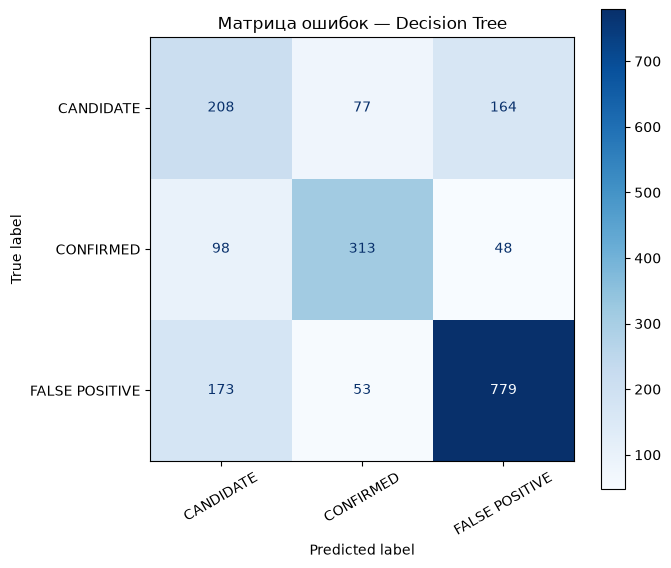

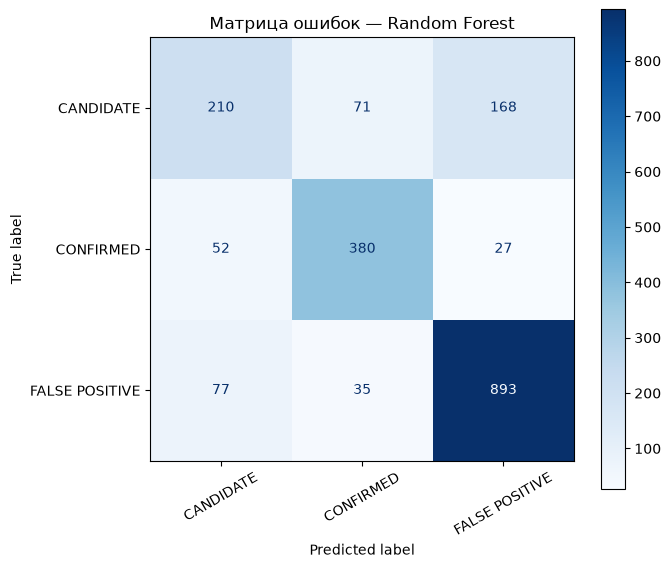

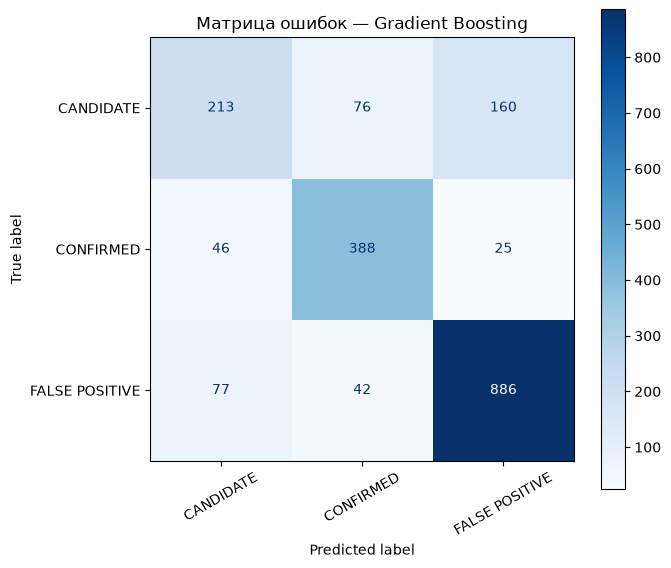

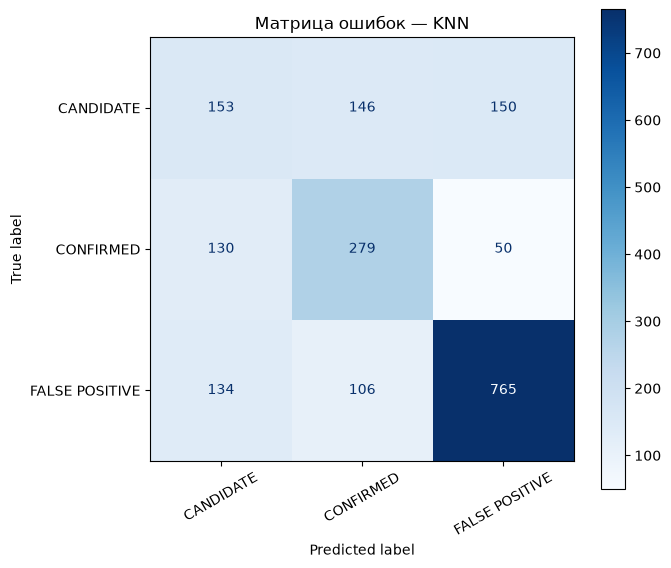

In [28]:
class_order = sorted(y.unique())

for name, y_pred in predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_order,
        display_labels=class_order,
        cmap='Blues',
        values_format='d',
        xticks_rotation=30,
        ax=ax
    )

    ax.set_title(f'Матрица ошибок — {name}')

    plt.tight_layout()
    plt.savefig(
        f'confusion_matrix_{name.lower().replace(" ", "_")}.png',
        dpi=300
    )
    plt.show()

In [29]:
# Предобработка только на обучающей выборке
visual_imputer = SimpleImputer(strategy='median')

X_train_vis = visual_imputer.fit_transform(X_train)
X_test_vis = visual_imputer.transform(X_test)

visual_scaler = StandardScaler()

X_train_vis = visual_scaler.fit_transform(X_train_vis)
X_test_vis = visual_scaler.transform(X_test_vis)

# PCA
visual_pca = PCA(n_components=2)

visual_pca.fit(X_train_vis)

X_test_2d = visual_pca.transform(X_test_vis)

print("Размерность тестовой выборки:", X_test_2d.shape)
print(
    "Объяснённая дисперсия:",
    round(visual_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Размерность тестовой выборки: (1913, 2)
Объяснённая дисперсия: 36.32 %


In [30]:
colors = {
    'CONFIRMED': 'green',
    'CANDIDATE': 'orange',
    'FALSE POSITIVE': 'red'
}


def plot_test_comparison(y_original, y_pred, model_name):

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    datasets = [
        (y_original, 'Исходные метки'),
        (y_pred, 'Предсказанные метки')
    ]

    for ax, (labels, title) in zip(axes, datasets):

        labels = np.asarray(labels)

        for class_name in class_order:

            mask = labels == class_name

            ax.scatter(
                X_test_2d[mask, 0],
                X_test_2d[mask, 1],
                color=colors[class_name],
                label=class_name,
                alpha=0.6,
                s=20
            )

        ax.set_title(title)
        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.legend()
        ax.grid(alpha=0.2)

    fig.suptitle(
        f'Сравнение исходных и предсказанных классов — {model_name}',
        fontsize=13
    )

    plt.tight_layout()

    filename = f'test_comparison_{model_name.lower().replace(" ", "_")}.png'

    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

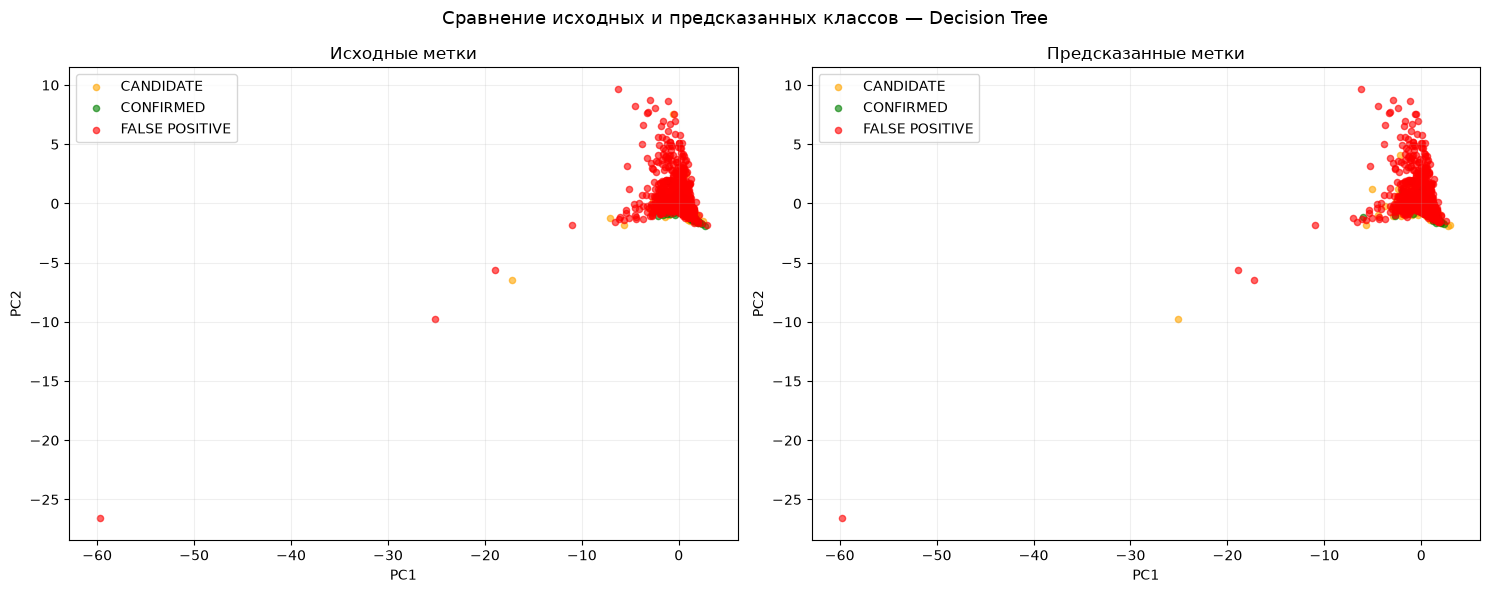

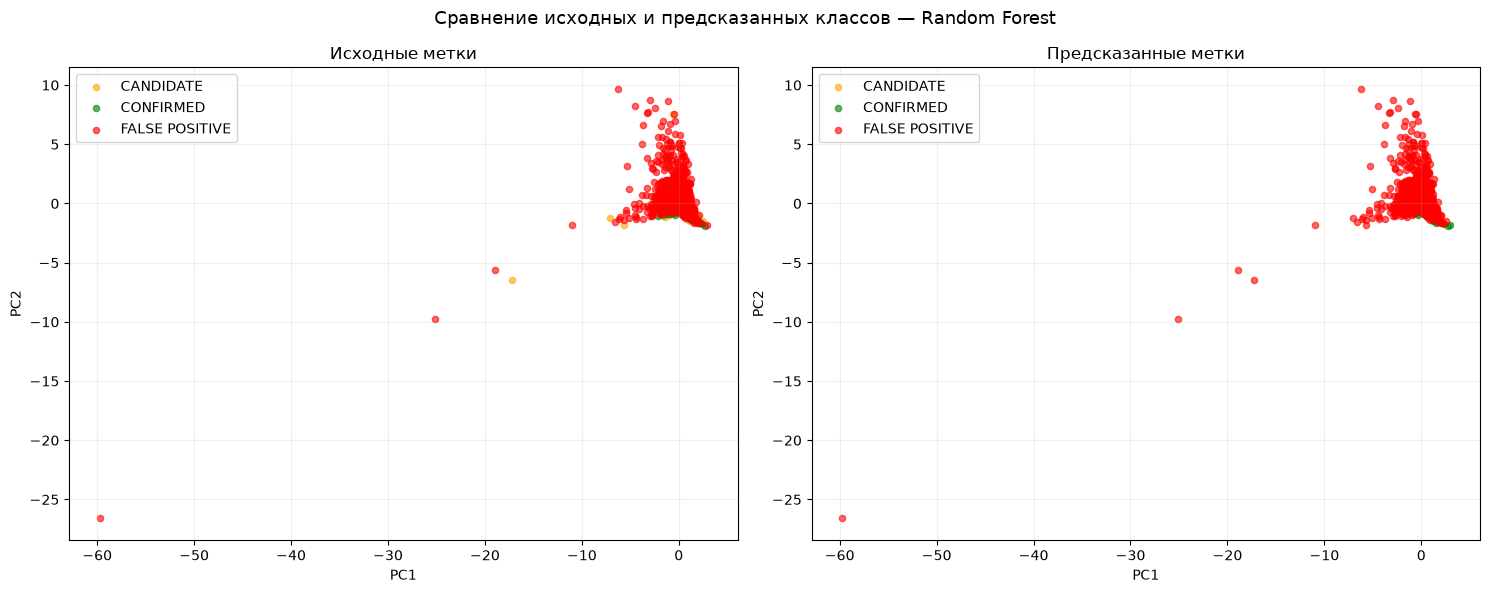

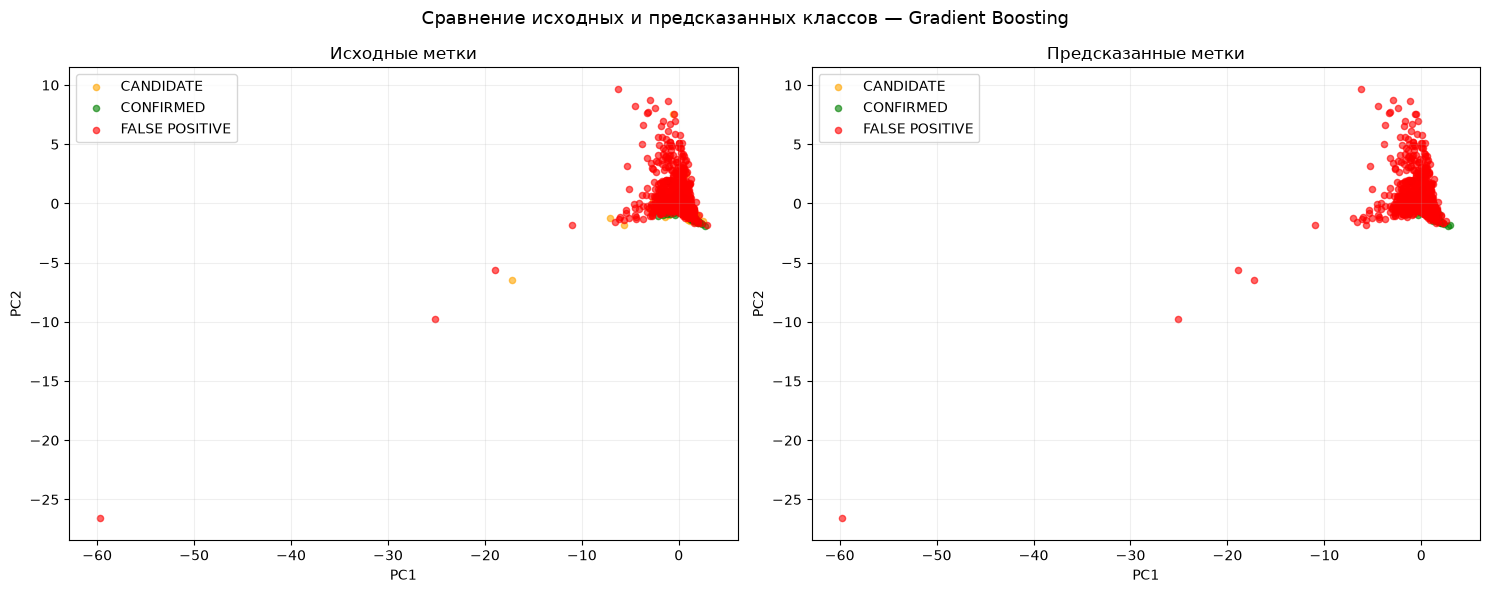

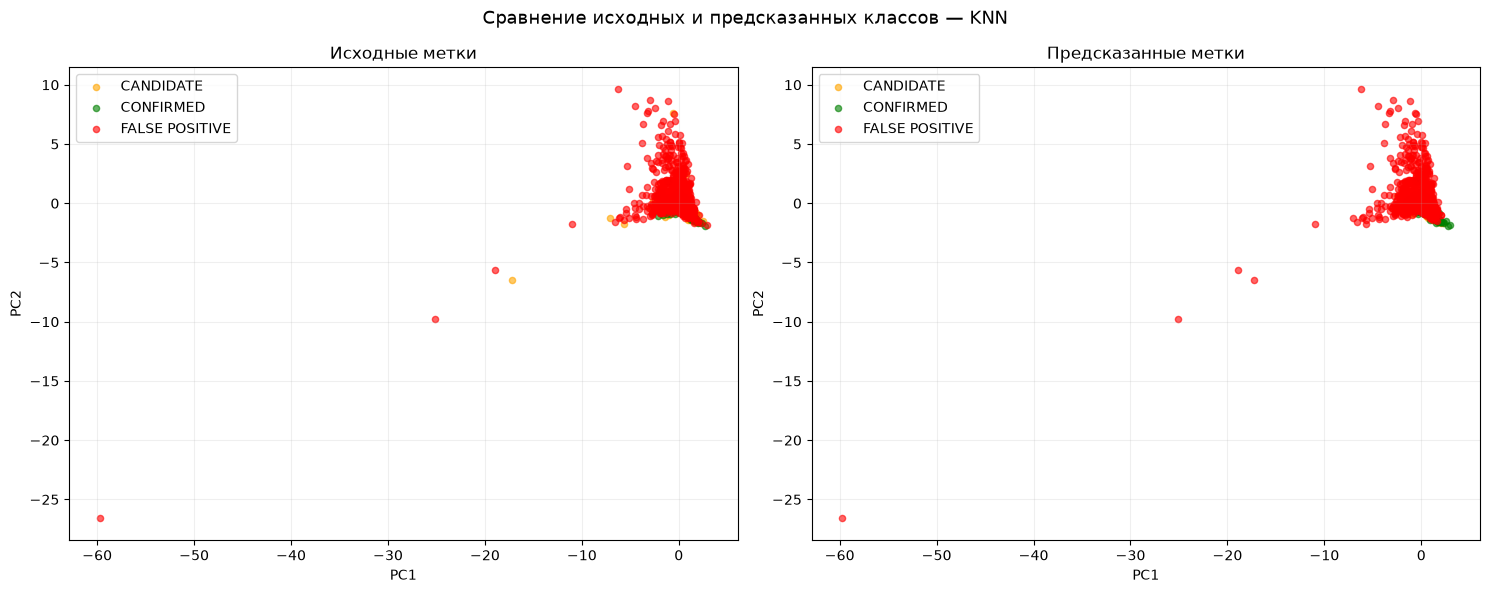

In [31]:
for name, y_pred in predictions.items():

    plot_test_comparison(
        y_test.to_numpy(),
        y_pred,
        name
    )

In [32]:
comparison = test_table.set_index('Модель')

comparison = comparison.sort_values(
    by='F1-score',
    ascending=False
)

display(comparison.round(4))

# Сохраняем результаты
comparison.to_csv(
    'classification_results_default.csv',
    encoding='utf-8-sig'
)

,Accuracy,Precision,Recall,F1-score
Модель,,,,
Gradient Boosting,0.7773,0.7427,0.7338,0.7335
Random Forest,0.7752,0.7407,0.7280,0.7302
Decision Tree,0.6796,0.6423,0.6401,0.6410
KNN,0.6257,0.5617,0.5699,0.5645


In [33]:
from sklearn.model_selection import GridSearchCV
import joblib
import json

In [34]:
tree_params = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 10],
    'classifier__min_samples_leaf': [1, 2]
}

In [35]:
forest_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__max_features': ['sqrt', 0.8],
    'classifier__min_samples_leaf': [1, 2]
}

In [36]:
boosting_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__max_depth': [1, 2, 3],
    'classifier__subsample': [0.8, 1.0]
}

In [37]:
knn_params = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

In [38]:
param_grids = {
    'Decision Tree': tree_params,
    'Random Forest': forest_params,
    'Gradient Boosting': boosting_params,
    'KNN': knn_params
}

In [39]:
# Метрики для оценки моделей
grid_scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Словари для хранения результатов
grid_searches = {}
best_models = {}

grid_summary = []
all_grid_results = []

# Запускаем подбор параметров для каждой модели
for name, model in models.items():

    print("\n" + "=" * 60)
    print(f"Настройка модели: {name}")
    print("=" * 60)

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=grid_scoring,
        refit='f1',
        cv=cv,
        n_jobs=-1,
        verbose=1,
        return_train_score=False
    )

    # Подбор параметров на обучающей выборке
    search.fit(X_train, y_train)

    # Сохраняем результаты
    grid_searches[name] = search
    best_models[name] = search.best_estimator_

    # Индекс лучшей комбинации
    best_idx = search.best_index_

    grid_summary.append({
        'Модель': name,
        'Accuracy': search.cv_results_['mean_test_accuracy'][best_idx],
        'Precision': search.cv_results_['mean_test_precision'][best_idx],
        'Recall': search.cv_results_['mean_test_recall'][best_idx],
        'F1-score': search.best_score_,
        'Лучшие параметры': str(search.best_params_)
    })

    # Сохраняем результаты всех комбинаций
    results = pd.DataFrame(search.cv_results_)
    results['Модель'] = name

    all_grid_results.append(results)

    print("\nЛучшие параметры:")
    print(search.best_params_)

    print("\nЛучший F1-score:", round(search.best_score_, 4))


Настройка модели: Decision Tree
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Лучшие параметры:
{'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 10}

Лучший F1-score: 0.6706

Настройка модели: Random Forest
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Лучшие параметры:
{'classifier__max_depth': 10, 'classifier__max_features': 0.8, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

Лучший F1-score: 0.7064

Настройка модели: Gradient Boosting
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Лучшие параметры:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__subsample': 1.0}

Лучший F1-score: 0.7149

Настройка модели: KNN
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Лучшие параметры:
{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 11, 'classifier__wei

In [40]:
grid_table = pd.DataFrame(grid_summary)

grid_table = grid_table.sort_values(
    by='F1-score',
    ascending=False
)

display(grid_table.round(4))

,Модель,Accuracy,Precision,Recall,F1-score,Лучшие параметры
2,Gradient Boosting,0.7604,0.7183,0.7182,0.7149,"{'classifier__learning_rate': 0.1, 'classifier..."
1,Random Forest,0.7556,0.7142,0.7121,0.7064,"{'classifier__max_depth': 10, 'classifier__max..."
0,Decision Tree,0.7132,0.6674,0.6799,0.6706,"{'classifier__criterion': 'gini', 'classifier_..."
3,KNN,0.6586,0.5880,0.5973,0.5870,"{'classifier__metric': 'manhattan', 'classifie..."


<Figure size 1100x600 with 0 Axes>

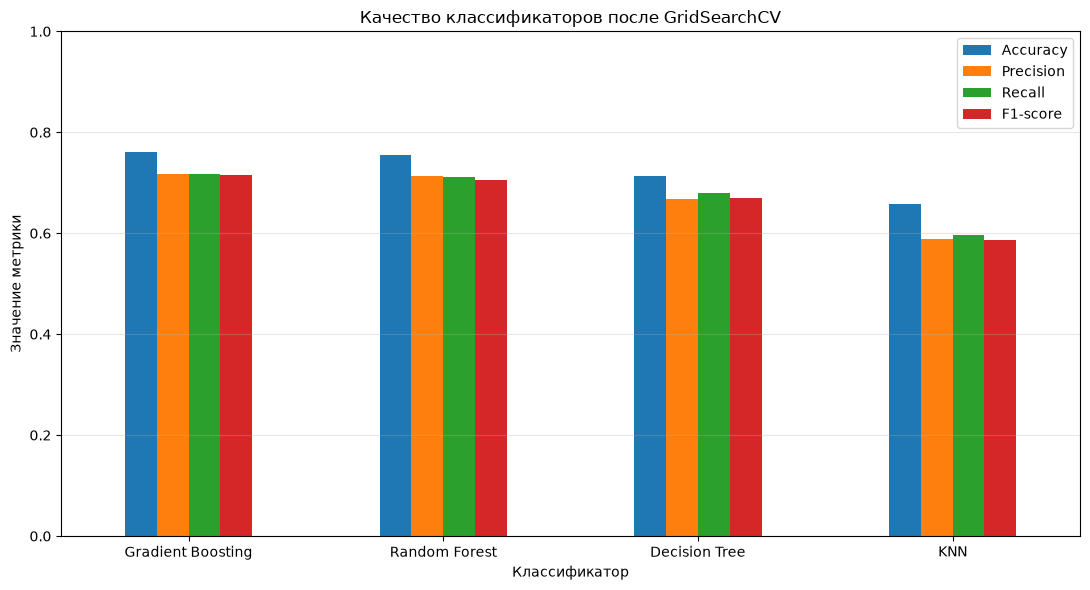

In [41]:
plt.figure(figsize=(11, 6))

grid_table.set_index('Модель')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Качество классификаторов после GridSearchCV')
plt.xlabel('Классификатор')
plt.ylabel('Значение метрики')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('gridsearch_comparison.png', dpi=300)
plt.show()

In [42]:
best_params = {
    name: search.best_params_
    for name, search in grid_searches.items()
}

with open(
    'best_params.json',
    'w',
    encoding='utf-8'
) as file:
    json.dump(
        best_params,
        file,
        ensure_ascii=False,
        indent=4
    )

In [43]:
joblib.dump(best_models, 'best_models.joblib')

['best_models.joblib']

In [44]:
grid_table.to_csv(
    'gridsearch_best_results.csv',
    index=False,
    encoding='utf-8-sig'
)

pd.concat(
    all_grid_results,
    ignore_index=True
).to_csv(
    'gridsearch_all_results.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Все результаты успешно сохранены!")

Все результаты успешно сохранены!


In [45]:
import joblib

best_models = joblib.load('best_models.joblib')

print("Оптимизированные модели загружены:")
for name in best_models:
    print(name)

Оптимизированные модели загружены:
Decision Tree
Random Forest
Gradient Boosting
KNN


In [46]:
tuned_predictions = {}
tuned_results = []

for name, model in best_models.items():

    print(f"Классификация: {name}")

    # Предсказание на тестовой выборке
    y_pred = model.predict(X_test)

    tuned_predictions[name] = y_pred

    # Расчёт метрик
    tuned_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ),
        'F1-score': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        )
    })

tuned_test_table = pd.DataFrame(tuned_results)

display(tuned_test_table.round(4))

Классификация: Decision Tree
Классификация: Random Forest
Классификация: Gradient Boosting
Классификация: KNN


,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7266,0.6819,0.6987,0.6873
1,Random Forest,0.7752,0.7364,0.7322,0.7271
2,Gradient Boosting,0.7705,0.7316,0.7274,0.7261
3,KNN,0.6759,0.6033,0.6148,0.6024


In [47]:
for name, y_pred in tuned_predictions.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Decision Tree
                precision    recall  f1-score   support

     CANDIDATE       0.52      0.46      0.49       449
     CONFIRMED       0.70      0.84      0.76       459
FALSE POSITIVE       0.83      0.79      0.81      1005

      accuracy                           0.73      1913
     macro avg       0.68      0.70      0.69      1913
  weighted avg       0.73      0.73      0.72      1913


Random Forest
                precision    recall  f1-score   support

     CANDIDATE       0.63      0.45      0.52       449
     CONFIRMED       0.74      0.87      0.80       459
FALSE POSITIVE       0.83      0.88      0.86      1005

      accuracy                           0.78      1913
     macro avg       0.74      0.73      0.73      1913
  weighted avg       0.76      0.78      0.76      1913


Gradient Boosting
                precision    recall  f1-score   support

     CANDIDATE       0.60      0.47      0.53       449
     CONFIRMED       0.77      0.84      0.80   

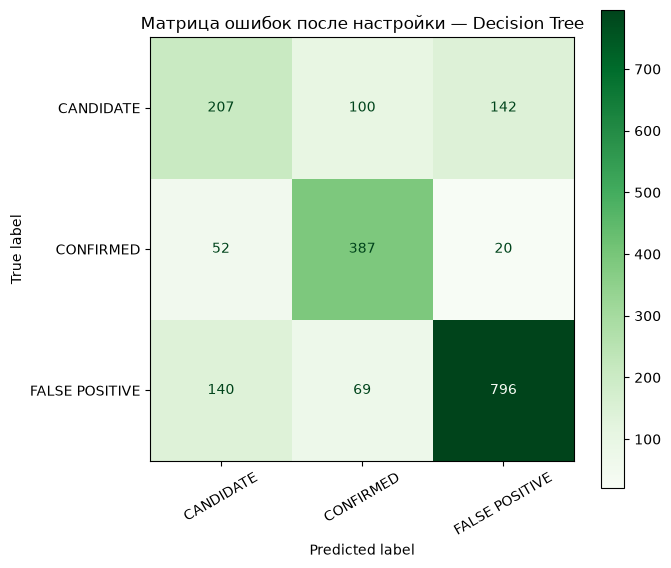

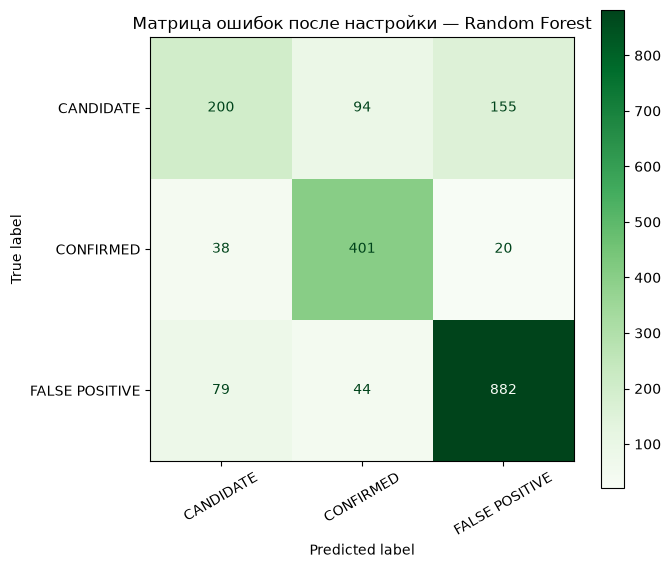

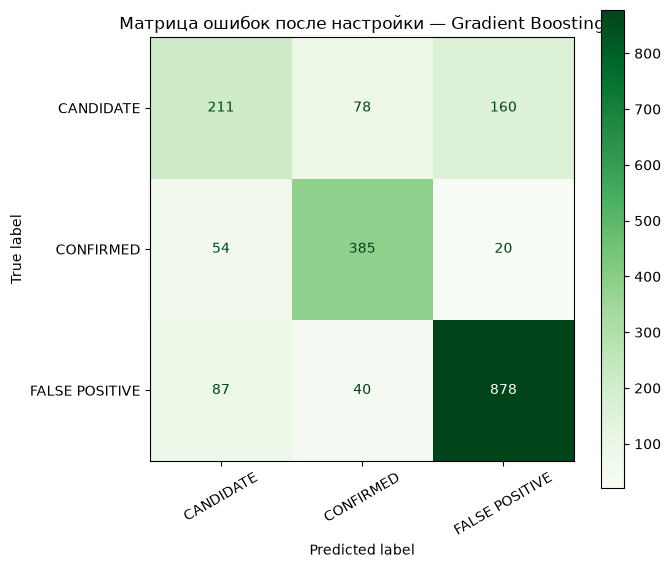

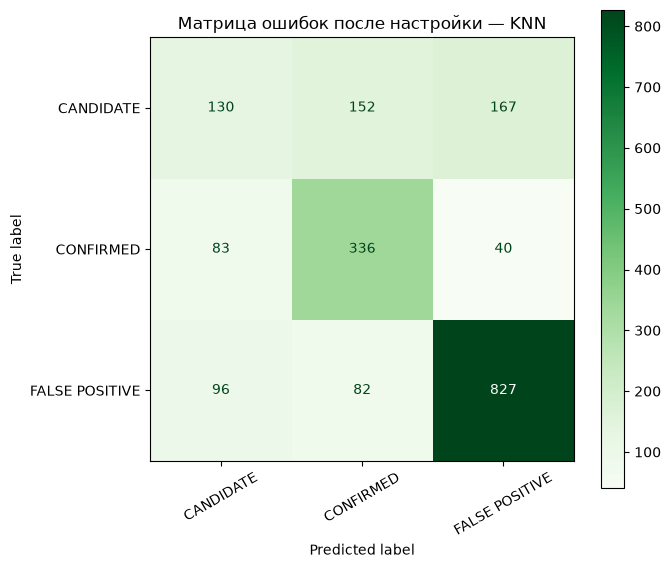

In [48]:
class_order = sorted(y.unique())

for name, y_pred in tuned_predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_order,
        display_labels=class_order,
        cmap='Greens',
        values_format='d',
        xticks_rotation=30,
        ax=ax
    )

    ax.set_title(
        f'Матрица ошибок после настройки — {name}'
    )

    plt.tight_layout()

    filename = (
        f'optimized_confusion_{name.lower().replace(" ", "_")}.png'
    )

    plt.savefig(filename, dpi=300)
    plt.show()

In [49]:
def plot_optimized_comparison(
    y_original,
    y_default,
    y_optimized,
    model_name
):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(20, 6)
    )

    datasets = [
        (y_original, 'Исходные метки'),
        (y_default, 'Предсказания до настройки'),
        (y_optimized, 'Предсказания после настройки')
    ]

    for ax, (labels, title) in zip(axes, datasets):

        labels = np.asarray(labels)

        for class_name in class_order:

            mask = labels == class_name

            ax.scatter(
                X_test_2d[mask, 0],
                X_test_2d[mask, 1],
                color=colors[class_name],
                label=class_name,
                alpha=0.6,
                s=20
            )

        ax.set_title(title)
        ax.set_xlabel('PC1')
        ax.set_ylabel('PC2')
        ax.legend()
        ax.grid(alpha=0.2)

    fig.suptitle(
        f'Сравнение классификации — {model_name}',
        fontsize=14
    )

    plt.tight_layout()

    filename = (
        f'optimized_comparison_{model_name.lower().replace(" ", "_")}.png'
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

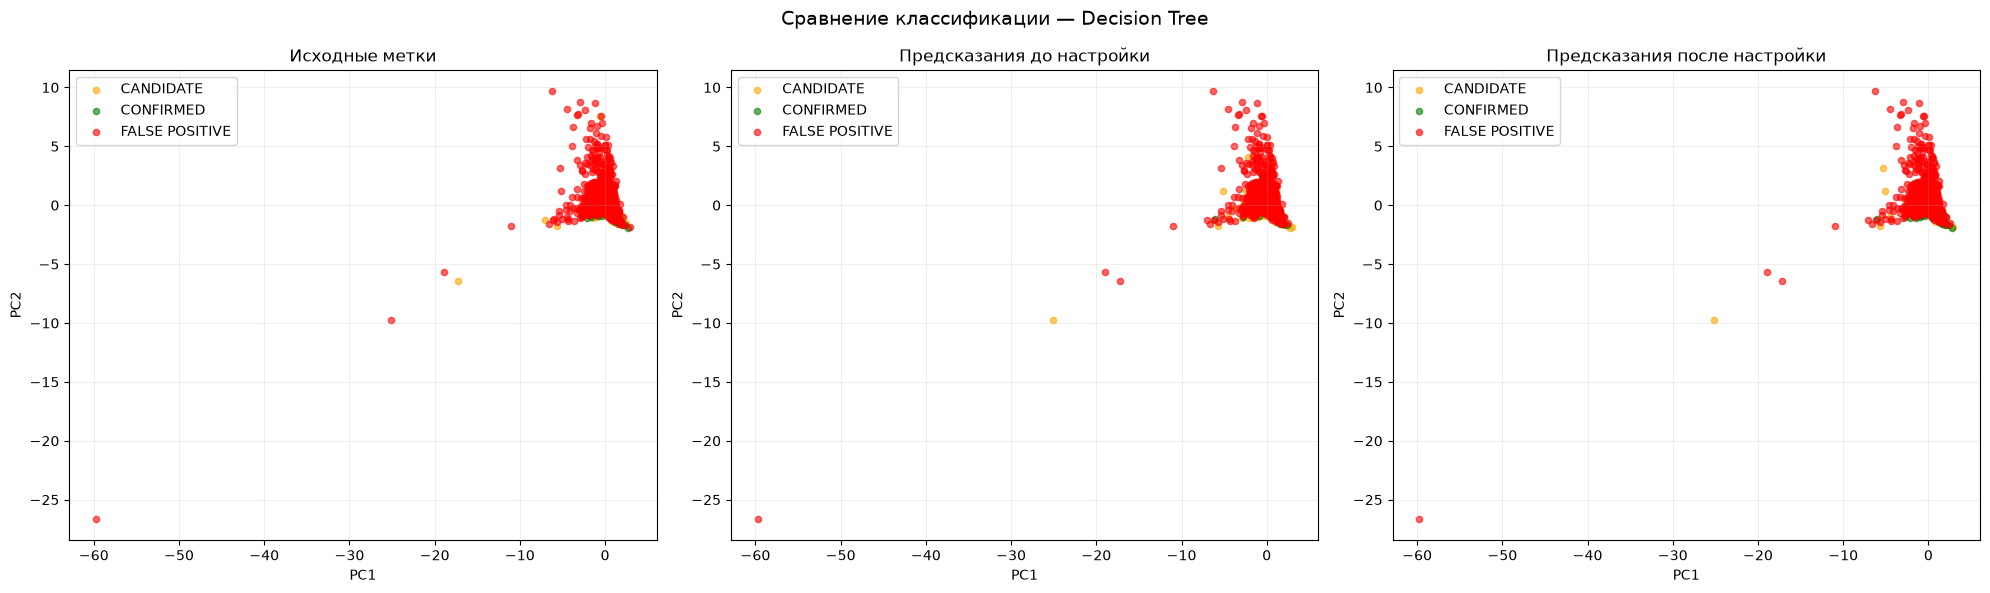

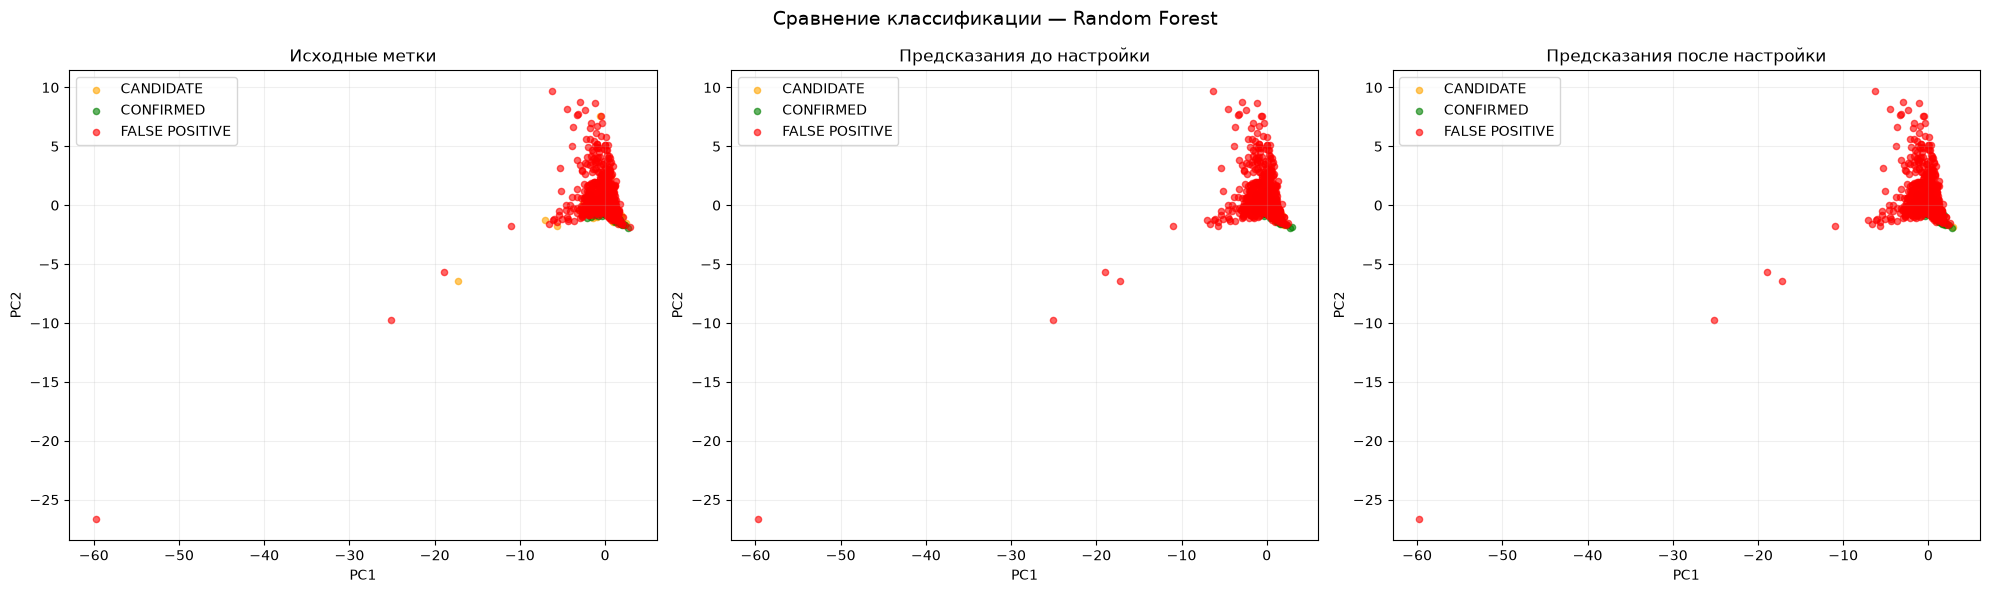

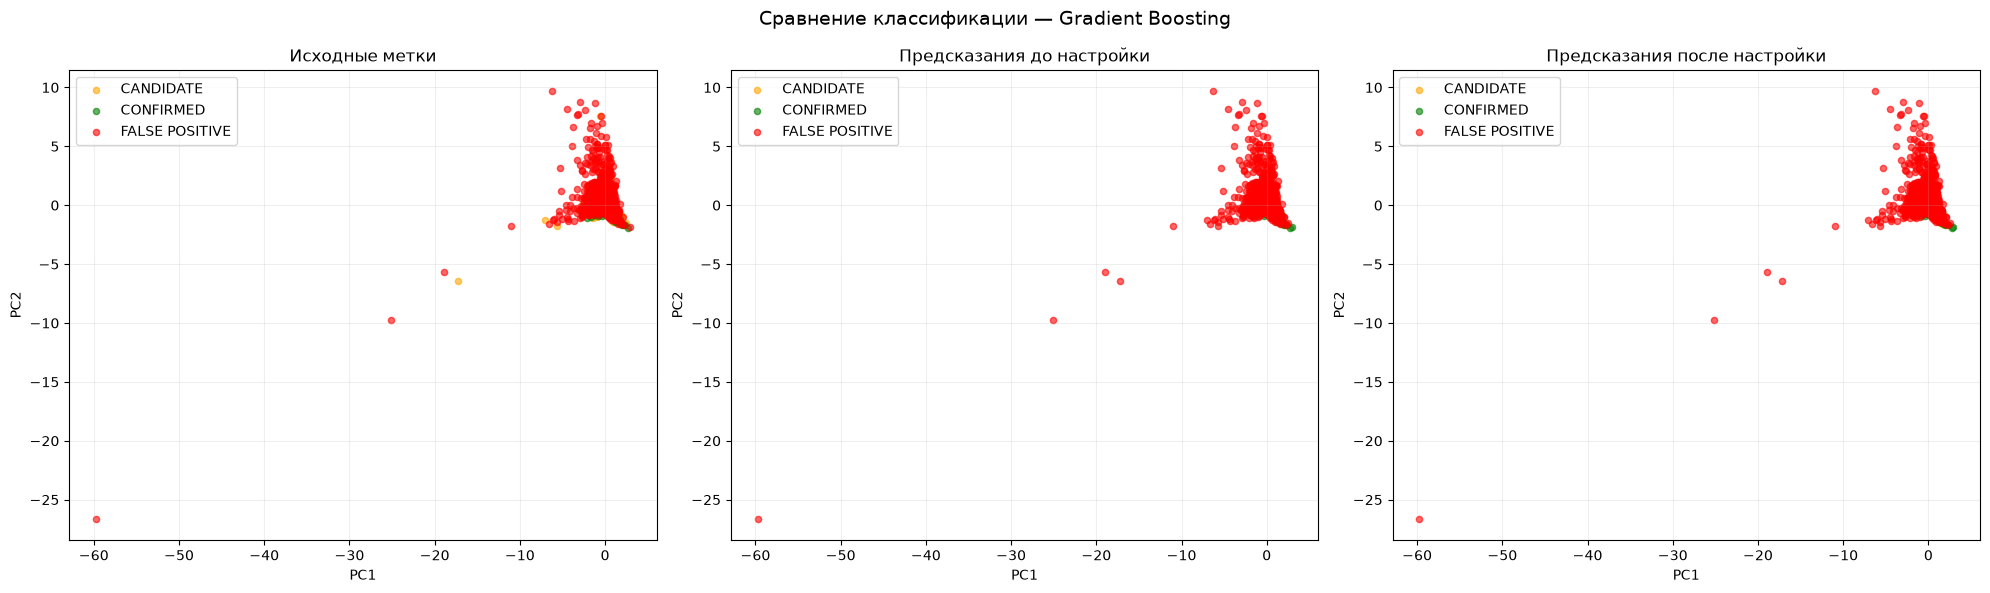

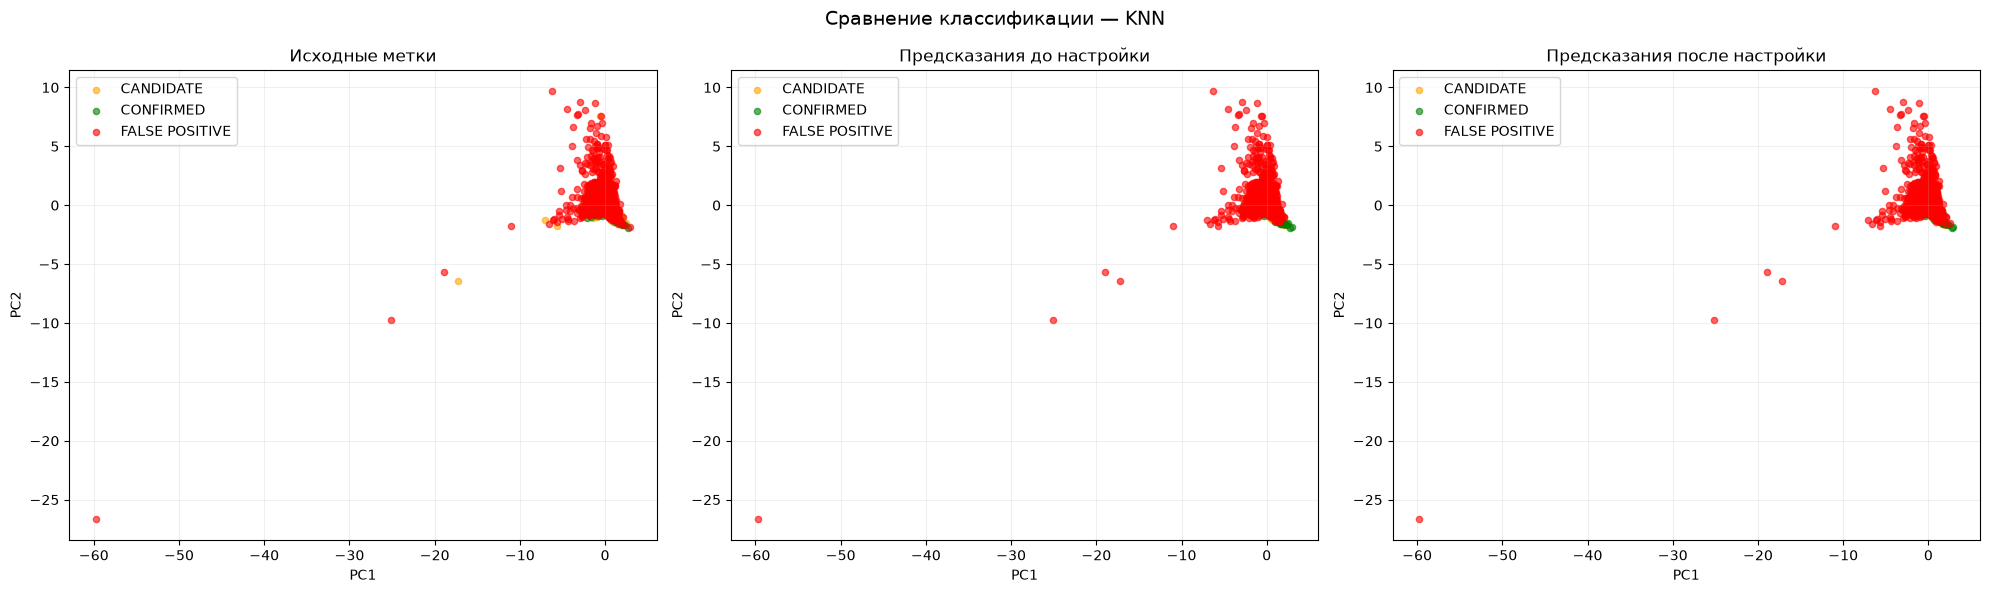

In [50]:
for name in tuned_predictions:

    plot_optimized_comparison(
        y_test.to_numpy(),
        predictions[name],
        tuned_predictions[name],
        name
    )

In [52]:
comparison_all = test_table.merge(
    tuned_test_table,
    on='Модель',
    suffixes=('_до', '_после')
)

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score'
]

for metric in metrics:

    comparison_all[f'{metric}_изменение'] = (
        comparison_all[f'{metric}_после']
        - comparison_all[f'{metric}_до']
    )

display(comparison_all.round(4))

,Модель,Accuracy_до,Precision_до,Recall_до,F1-score_до,Accuracy_после,Precision_после,Recall_после,F1-score_после,Accuracy_изменение,Precision_изменение,Recall_изменение,F1-score_изменение
0,Decision Tree,0.6796,0.6423,0.6401,0.6410,0.7266,0.6819,0.6987,0.6873,0.0470,0.0396,0.0586,0.0463
1,Random Forest,0.7752,0.7407,0.7280,0.7302,0.7752,0.7364,0.7322,0.7271,0.0000,-0.0043,0.0042,-0.0031
2,Gradient Boosting,0.7773,0.7427,0.7338,0.7335,0.7705,0.7316,0.7274,0.7261,-0.0068,-0.0111,-0.0063,-0.0073
3,KNN,0.6257,0.5617,0.5699,0.5645,0.6759,0.6033,0.6148,0.6024,0.0502,0.0416,0.0449,0.0379


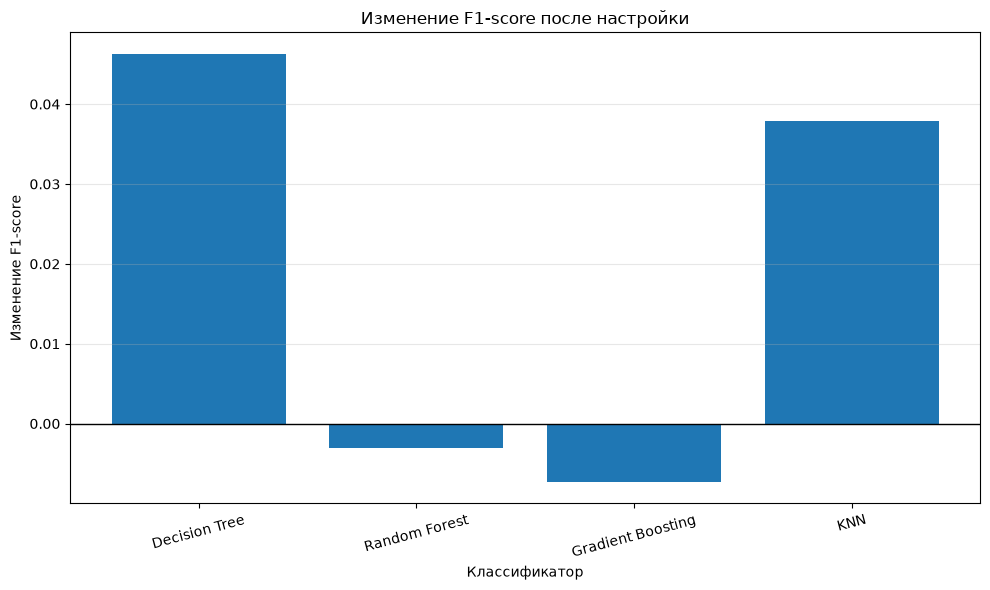

In [53]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_all['Модель'],
    comparison_all['F1-score_изменение']
)

plt.axhline(
    0,
    color='black',
    linewidth=1
)

plt.title('Изменение F1-score после настройки')
plt.xlabel('Классификатор')
plt.ylabel('Изменение F1-score')

plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig('f1_improvement.png', dpi=300)
plt.show()

In [54]:
tuned_test_table.to_csv(
    'optimized_results.csv',
    index=False,
    encoding='utf-8-sig'
)

comparison_all.to_csv(
    'comparison_before_after.csv',
    index=False,
    encoding='utf-8-sig'
)

joblib.dump(
    best_models,
    'optimized_models_final.joblib'
)

print("Результаты четвёртого пункта сохранены!")

Результаты четвёртого пункта сохранены!


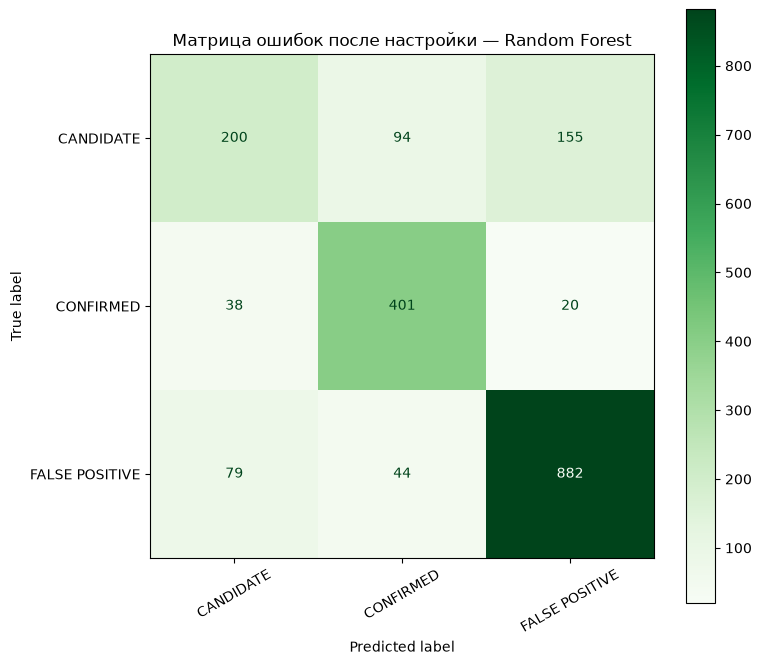

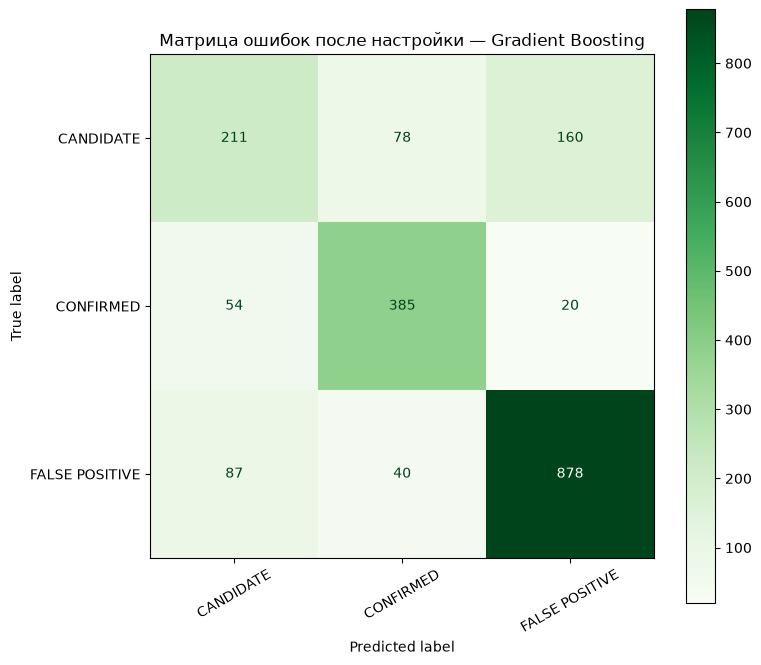

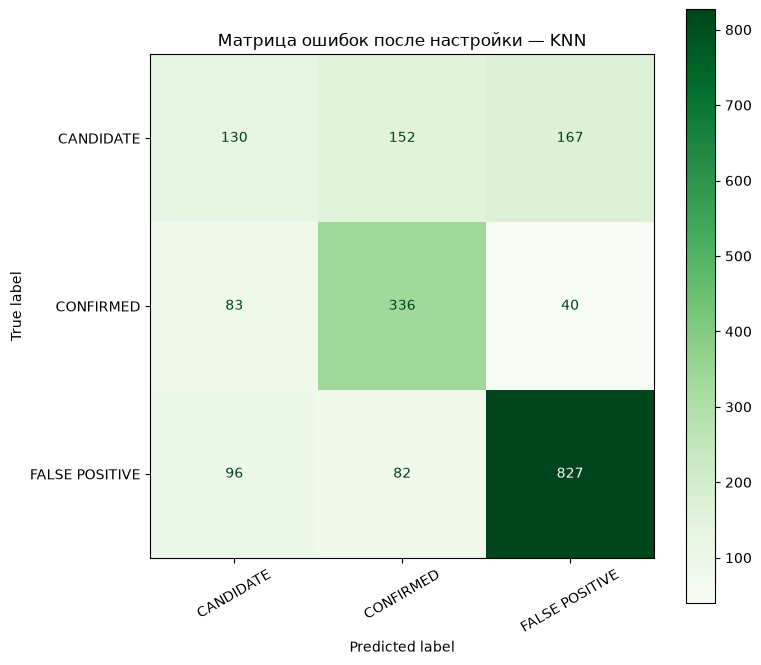

In [55]:
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

Path("results").mkdir(exist_ok=True)

# Строим матрицы ошибок для остальных классификаторов
for name in ['Random Forest', 'Gradient Boosting', 'KNN']:

    y_pred = tuned_predictions[name]

    fig, ax = plt.subplots(figsize=(8, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_order,
        display_labels=class_order,
        cmap='Greens',
        values_format='d',
        xticks_rotation=30,
        ax=ax
    )

    ax.set_title(f'Матрица ошибок после настройки — {name}')

    plt.tight_layout()

    filename = name.lower().replace(' ', '_')

    plt.savefig(
        f'results/optimized_confusion_{filename}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

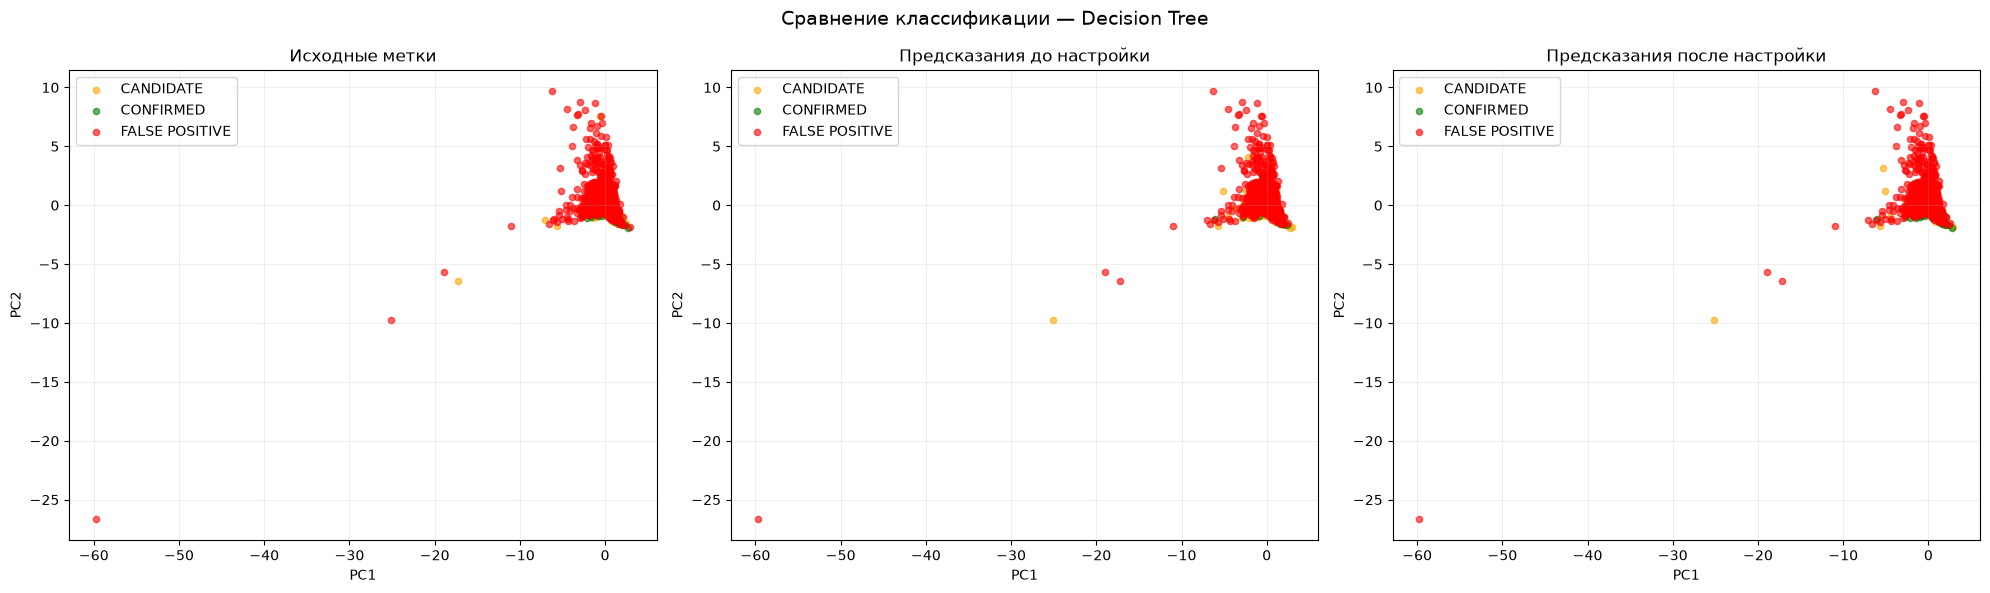

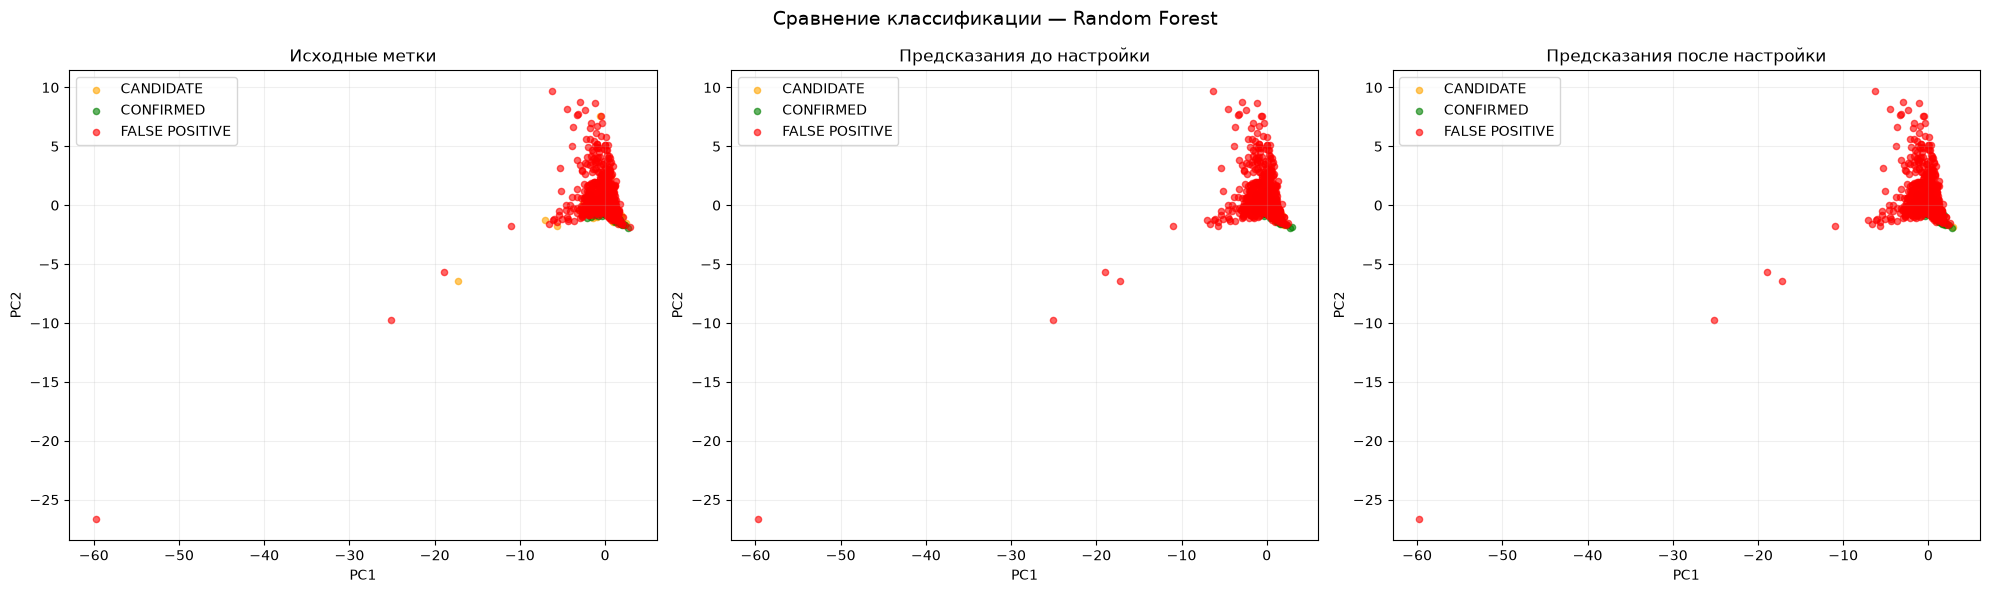

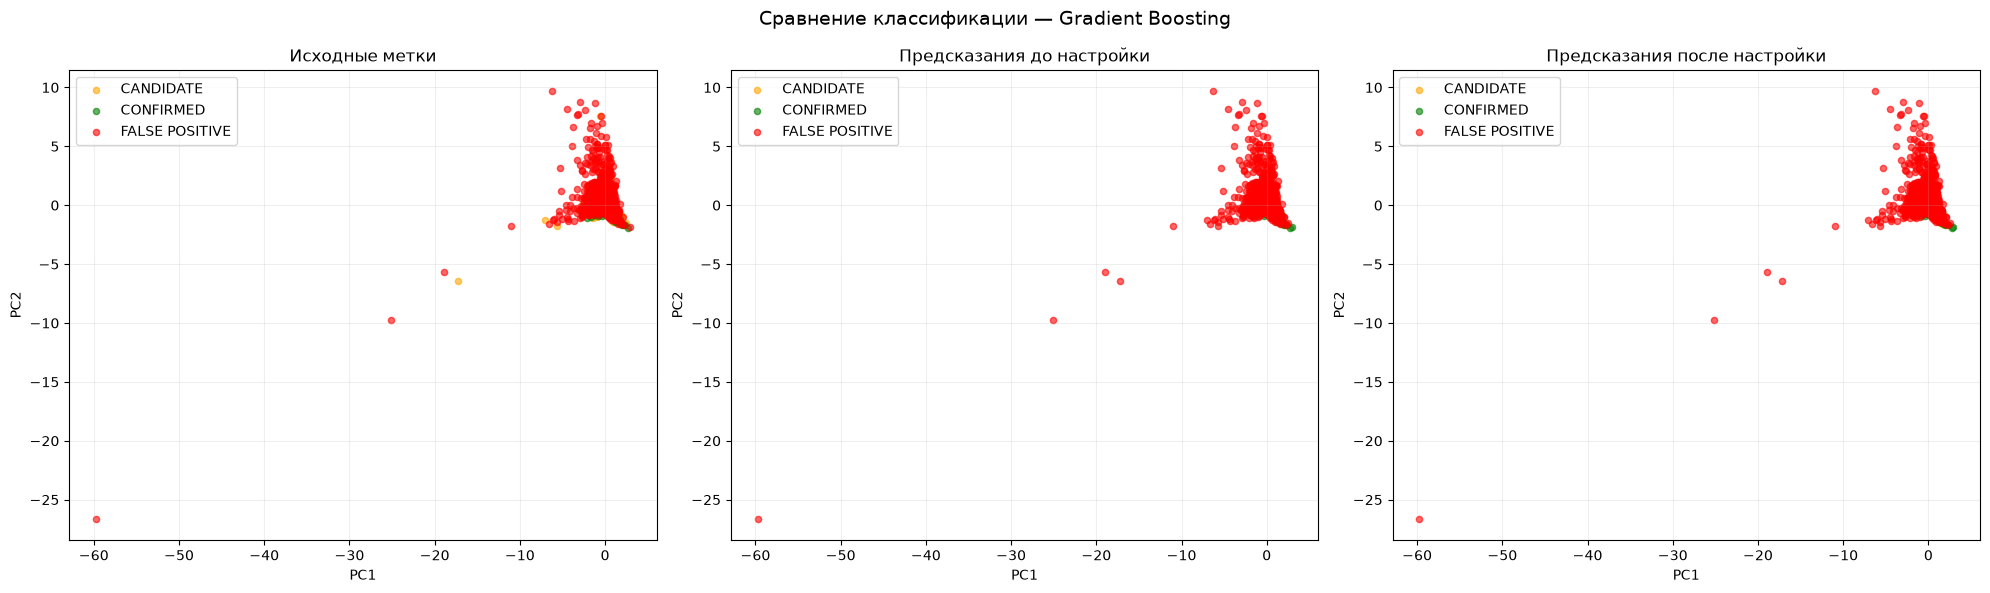

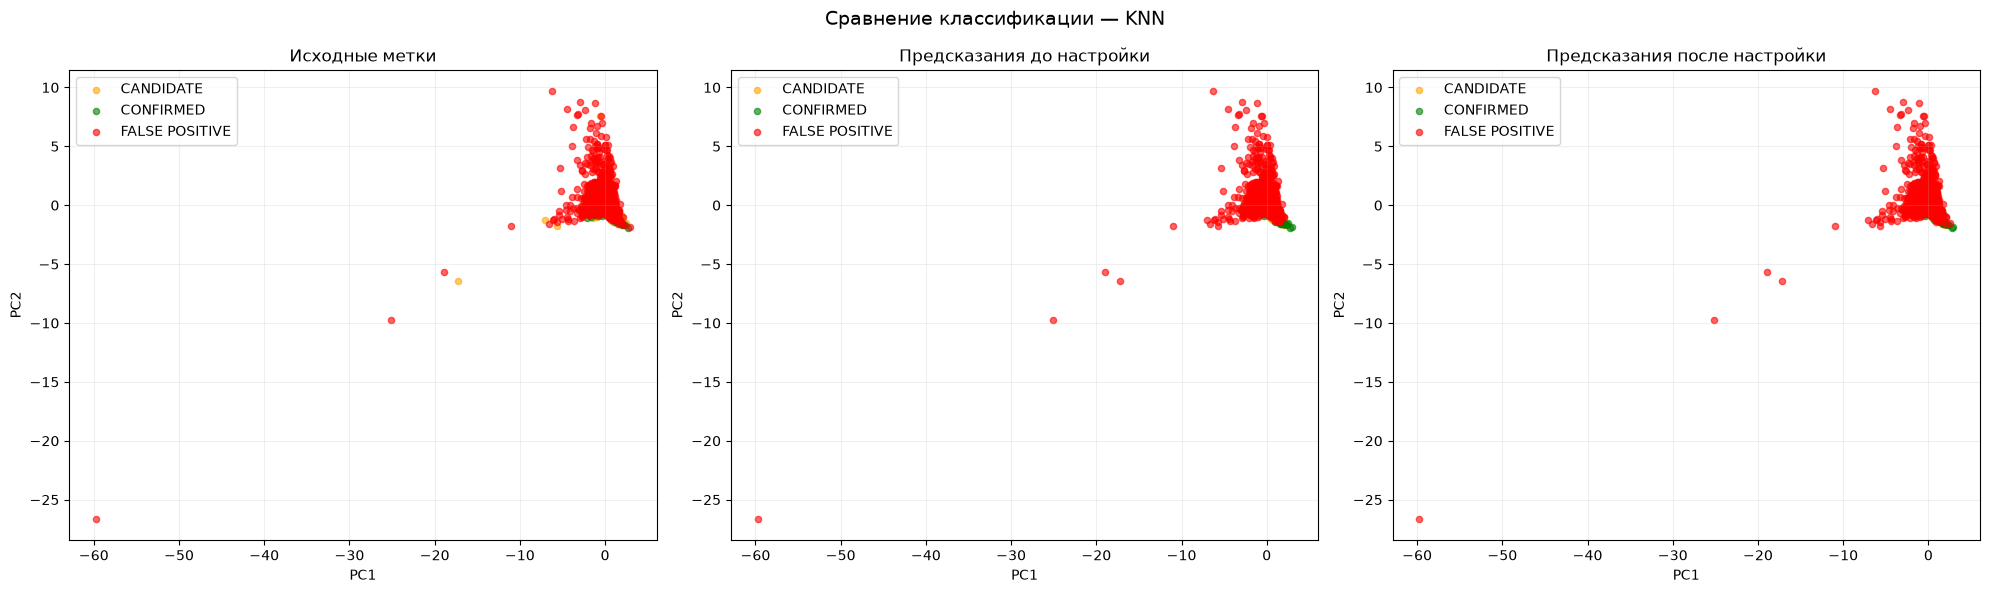

In [56]:
for name in tuned_predictions:

    plot_optimized_comparison(
        y_test.to_numpy(),
        predictions[name],
        tuned_predictions[name],
        name
    )

In [57]:
import shutil
from pathlib import Path

Path("results").mkdir(exist_ok=True)

# Сохраняем таблицы
comparison_all.to_csv(
    "results/comparison_before_after.csv",
    index=False,
    encoding="utf-8-sig"
)

tuned_test_table.to_csv(
    "results/optimized_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Результаты сохранены!")

Результаты сохранены!


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Путь к датасету
DATA_PATH = Path(
    r"C:\Users\yaros_tm2sc6p\Рабочий стол\Учёба\ИАД\Labs\LR3\Datasets\Barotrop.csv"
)

# Проверка существования файла
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не найден: {DATA_PATH}")

# Загрузка данных
barotrop_df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')

print("Датасет успешно загружен!")
print("Размер датасета:", barotrop_df.shape)

display(barotrop_df.head())

Датасет успешно загружен!
Размер датасета: (37, 3)


,LONGITUD,LATITUDE,CLASS
0,59.0,17.0,100.0
1,59.5,21.0,100.0
2,60.0,12.0,100.0
3,60.5,16.0,100.0
4,61.0,13.0,100.0


In [2]:
print("Информация о датасете:")
barotrop_df.info()

print("\nРаспределение классов:")
print(barotrop_df['CLASS'].value_counts().sort_index())

print("\nПропущенные значения:")
print(barotrop_df.isnull().sum())

print("\nСтатистические характеристики:")
display(barotrop_df.describe())

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LONGITUD  37 non-null     float64
 1   LATITUDE  37 non-null     float64
 2   CLASS     37 non-null     float64
dtypes: float64(3)
memory usage: 1020.0 bytes

Распределение классов:
CLASS
100.0    19
101.0    18
Name: count, dtype: int64

Пропущенные значения:
LONGITUD    0
LATITUDE    0
CLASS       0
dtype: int64

Статистические характеристики:


,LONGITUD,LATITUDE,CLASS
count,37.000000,37.000000,37.000000
mean,65.432432,16.216216,100.486486
std,3.438269,2.709399,0.506712
min,59.000000,12.000000,100.000000
25%,63.000000,14.000000,100.000000
50%,65.500000,16.000000,100.000000
75%,68.000000,18.000000,101.000000
max,71.500000,21.000000,101.000000


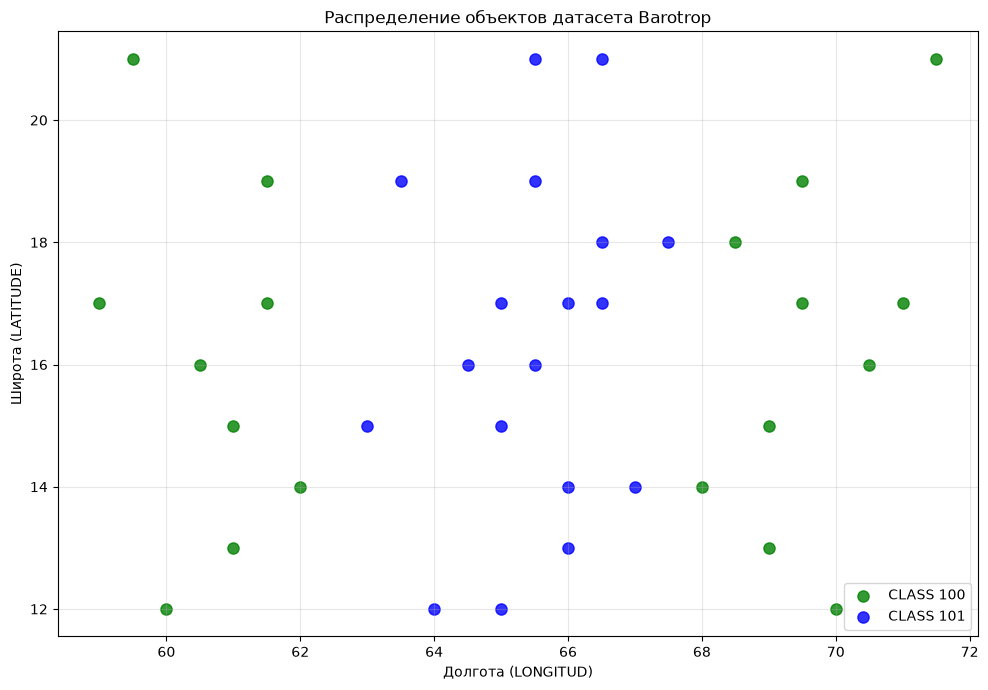

In [3]:
plt.figure(figsize=(10, 7))

colors = {
    100: 'green',
    101: 'blue'
}

for class_value in sorted(barotrop_df['CLASS'].unique()):

    subset = barotrop_df[
        barotrop_df['CLASS'] == class_value
    ]

    plt.scatter(
        subset['LONGITUD'],
        subset['LATITUDE'],
        label=f'CLASS {int(class_value)}',
        color=colors[class_value],
        s=65,
        alpha=0.8
    )

plt.title('Распределение объектов датасета Barotrop')
plt.xlabel('Долгота (LONGITUD)')
plt.ylabel('Широта (LATITUDE)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('Barotrop_distribution.png', dpi=300)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Входные признаки
X_barotrop = barotrop_df[['LONGITUD', 'LATITUDE']].copy()

# Целевая переменная
y_barotrop = barotrop_df['CLASS'].copy()

print("Размер выборки:", X_barotrop.shape)
print("Количество классов:", y_barotrop.nunique())

print("\nРаспределение классов:")
print(y_barotrop.value_counts())

Размер выборки: (37, 2)
Количество классов: 2

Распределение классов:
CLASS
100.0    19
101.0    18
Name: count, dtype: int64


In [5]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_barotrop,
    y_barotrop,
    test_size=0.25,
    random_state=42,
    stratify=y_barotrop
)

print("Обучающая выборка:", X_train_b.shape)
print("Тестовая выборка:", X_test_b.shape)

print("\nКлассы обучающей выборки:")
print(y_train_b.value_counts())

print("\nКлассы тестовой выборки:")
print(y_test_b.value_counts())

Обучающая выборка: (27, 2)
Тестовая выборка: (10, 2)

Классы обучающей выборки:
CLASS
100.0    14
101.0    13
Name: count, dtype: int64

Классы тестовой выборки:
CLASS
100.0    5
101.0    5
Name: count, dtype: int64


In [6]:
barotrop_models = {
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', DecisionTreeClassifier(random_state=42))
    ]),

    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),

    'Gradient Boosting': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', GradientBoostingClassifier(random_state=42))
    ]),

    'KNN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier())
    ])
}

In [7]:
cv_barotrop = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

cv_results_barotrop = []

for name, model in barotrop_models.items():

    print(f"\nОбучение: {name}")

    scores = cross_validate(
        model,
        X_train_b,
        y_train_b,
        cv=cv_barotrop,
        scoring=scoring
    )

    cv_results_barotrop.append({
        'Модель': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-score': scores['test_f1'].mean()
    })

cv_table_barotrop = pd.DataFrame(cv_results_barotrop)

display(cv_table_barotrop.round(4))


Обучение: Decision Tree

Обучение: Random Forest

Обучение: Gradient Boosting

Обучение: KNN


,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.96,0.9750,0.9500,0.9524
1,Random Forest,0.96,0.9750,0.9500,0.9524
2,Gradient Boosting,0.96,0.9750,0.9500,0.9524
3,KNN,0.82,0.8767,0.8167,0.8031


In [8]:
barotrop_predictions = {}
barotrop_results = []

for name, model in barotrop_models.items():

    # Обучение
    model.fit(X_train_b, y_train_b)

    # Предсказание
    y_pred = model.predict(X_test_b)

    barotrop_predictions[name] = y_pred

    barotrop_results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test_b, y_pred),
        'Precision': precision_score(
            y_test_b, y_pred,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test_b, y_pred,
            average='macro',
            zero_division=0
        ),
        'F1-score': f1_score(
            y_test_b, y_pred,
            average='macro',
            zero_division=0
        )
    })

barotrop_test_table = pd.DataFrame(barotrop_results)

display(barotrop_test_table.round(4))

,Модель,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.9,0.9167,0.9,0.899
1,Random Forest,0.9,0.9167,0.9,0.899
2,Gradient Boosting,0.9,0.9167,0.9,0.899
3,KNN,0.8,0.8000,0.8,0.800


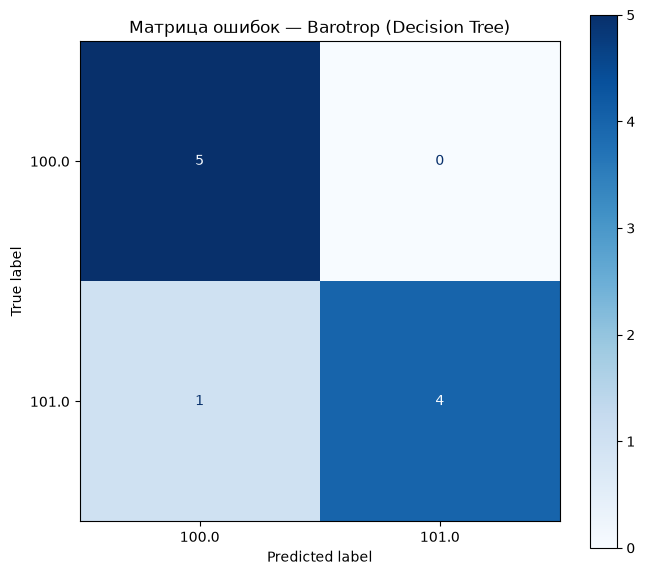

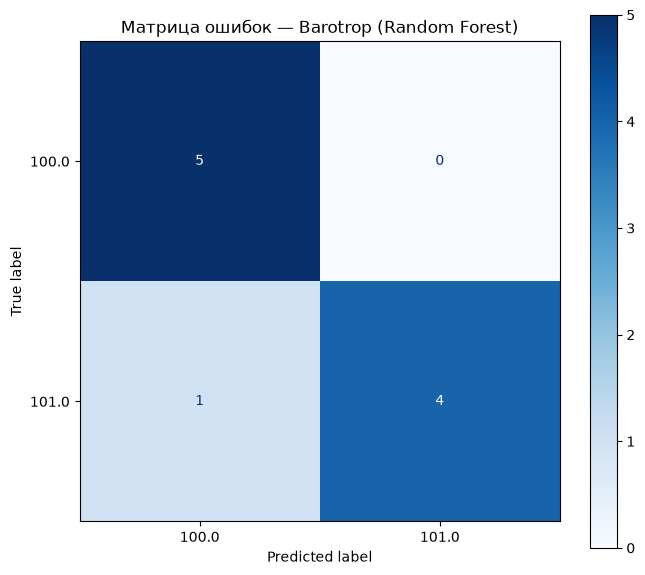

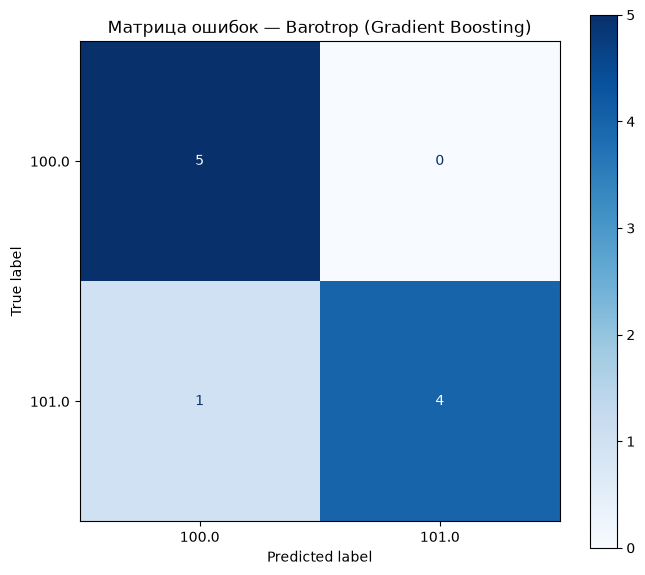

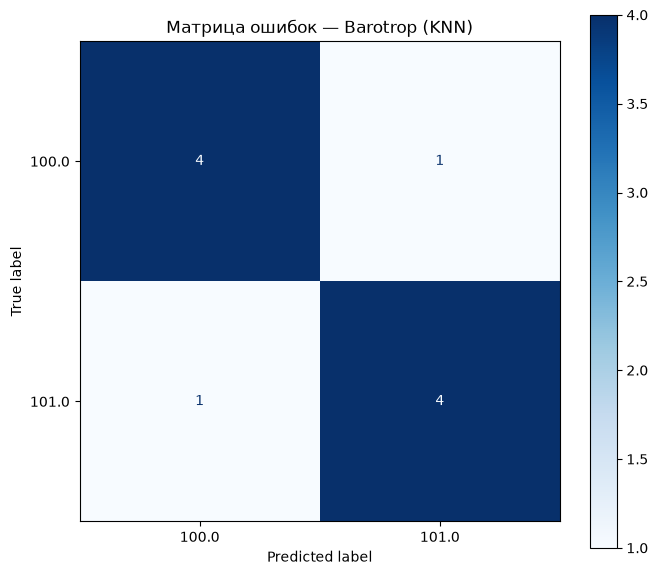

In [9]:
class_order_b = sorted(y_barotrop.unique())

for name, y_pred in barotrop_predictions.items():

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test_b,
        y_pred,
        labels=class_order_b,
        cmap='Blues',
        values_format='d',
        ax=ax
    )

    ax.set_title(f'Матрица ошибок — Barotrop ({name})')

    plt.tight_layout()
    plt.savefig(
        f'Barotrop_{name.lower().replace(" ", "_")}.png',
        dpi=300
    )
    plt.show()

<Figure size 1100x600 with 0 Axes>

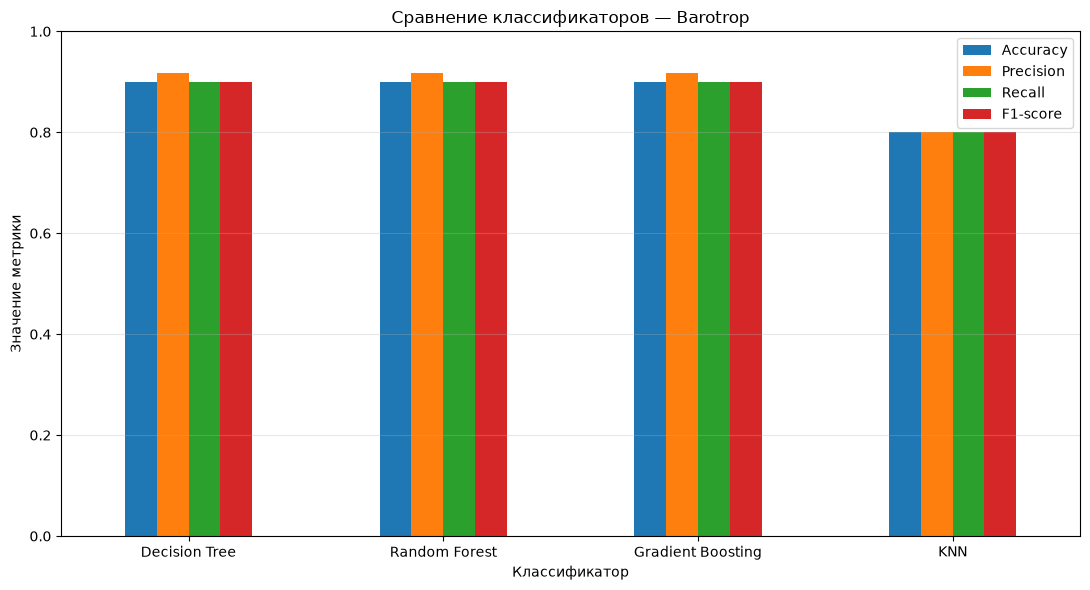

In [10]:
plt.figure(figsize=(11, 6))

barotrop_test_table.set_index('Модель')[
    ['Accuracy', 'Precision', 'Recall', 'F1-score']
].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Сравнение классификаторов — Barotrop')
plt.xlabel('Классификатор')
plt.ylabel('Значение метрики')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('Barotrop_comparison.png', dpi=300)
plt.show()